Today's learning objectives
1. Decision Tree – concept and working.
2. Decision Tree Regressor.
3. Decision Tree Classifier.
4. Random Forest – concept and working.
5. Random Forest Regressor and Classifier.
6. Practical implementation using Scikit-learn.
7. Compare model performance.
8. Understand which algorithm is useful in real-world Data Analysis.

##1. What is a Decision Tree?

###Decision Tree ek Machine Learning algorithm hai jo decisions lene ke liye tree-like structure use karta hai.

#Imagine karo tumhe decide karna hai ki student Pass hoga ya Fail.

##Study_Hour >= 5.5 hrs
###if Yes-> Pass
###if No-> Fail

#Important terminology:
- Root Node: Starting point of the tree.
- Decision Node: Where a condition is checked.
- Branch: Path based on the decision.
- Leaf Node: Final prediction.

#2. Types of Decision Tree
##Algorithm	Purpose
###Decision Tree Regressor	Predicts numerical values
###Decision Tree Classifier	Predicts categories

##Examples:
- House price prediction → Regressor.
- Customer churn prediction → Classifier.

#Part 2 – Practical: Decision Tree Regressor

#Step 1- Load Dataset


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes

# Load dataset
diabetes = load_diabetes()

# Convert dataset into DataFrame
df = pd.DataFrame(
    diabetes.data,
    columns=diabetes.feature_names
)

# Add target column
df["Disease_Progression"] = diabetes.target

print("Dataset Loaded Successfully!")
print("\nFirst 5 Rows:")
print(df.head())

print("\nDataset Shape:", df.shape)

Dataset Loaded Successfully!

First 5 Rows:
        age       sex       bmi        bp        s1        s2        s3  \
0  0.038076  0.050680  0.061696  0.021872 -0.044223 -0.034821 -0.043401   
1 -0.001882 -0.044642 -0.051474 -0.026328 -0.008449 -0.019163  0.074412   
2  0.085299  0.050680  0.044451 -0.005670 -0.045599 -0.034194 -0.032356   
3 -0.089063 -0.044642 -0.011595 -0.036656  0.012191  0.024991 -0.036038   
4  0.005383 -0.044642 -0.036385  0.021872  0.003935  0.015596  0.008142   

         s4        s5        s6  Disease_Progression  
0 -0.002592  0.019907 -0.017646                151.0  
1 -0.039493 -0.068332 -0.092204                 75.0  
2 -0.002592  0.002861 -0.025930                141.0  
3  0.034309  0.022688 -0.009362                206.0  
4 -0.002592 -0.031988 -0.046641                135.0  

Dataset Shape: (442, 11)


#Step 2 — Dataset Information

In [2]:
# Dataset information
print("Dataset Information:")
df.info()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Statistical summary
print("\nStatistical Summary:")
print(df.describe())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   age                  442 non-null    float64
 1   sex                  442 non-null    float64
 2   bmi                  442 non-null    float64
 3   bp                   442 non-null    float64
 4   s1                   442 non-null    float64
 5   s2                   442 non-null    float64
 6   s3                   442 non-null    float64
 7   s4                   442 non-null    float64
 8   s5                   442 non-null    float64
 9   s6                   442 non-null    float64
 10  Disease_Progression  442 non-null    float64
dtypes: float64(11)
memory usage: 38.1 KB

Missing Values:
age                    0
sex                    0
bmi                    0
bp                     0
s1                     0
s2                     0
s3             

#Step 3 — Features and Target

In [3]:
# Separate features (X) and target (y)

X = df.drop("Disease_Progression", axis=1)
y = df["Disease_Progression"]

print("Features (X) Shape:", X.shape)
print("Target (y) Shape:", y.shape)

print("\nInput Features:")
print(X.head())

print("\nTarget Values:")
print(y.head())

Features (X) Shape: (442, 10)
Target (y) Shape: (442,)

Input Features:
        age       sex       bmi        bp        s1        s2        s3  \
0  0.038076  0.050680  0.061696  0.021872 -0.044223 -0.034821 -0.043401   
1 -0.001882 -0.044642 -0.051474 -0.026328 -0.008449 -0.019163  0.074412   
2  0.085299  0.050680  0.044451 -0.005670 -0.045599 -0.034194 -0.032356   
3 -0.089063 -0.044642 -0.011595 -0.036656  0.012191  0.024991 -0.036038   
4  0.005383 -0.044642 -0.036385  0.021872  0.003935  0.015596  0.008142   

         s4        s5        s6  
0 -0.002592  0.019907 -0.017646  
1 -0.039493 -0.068332 -0.092204  
2 -0.002592  0.002861 -0.025930  
3  0.034309  0.022688 -0.009362  
4 -0.002592 -0.031988 -0.046641  

Target Values:
0    151.0
1     75.0
2    141.0
3    206.0
4    135.0
Name: Disease_Progression, dtype: float64


#Step 4 — Train-Test Split

In [4]:
from sklearn.model_selection import train_test_split

# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

# Check dataset shapes
print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (353, 10)
Testing Features: (89, 10)
Training Target: (353,)
Testing Target: (89,)


#Step 5: Decision Tree Regressor

In [5]:
from sklearn.tree import DecisionTreeRegressor

# Create Decision Tree Regressor
dt_model = DecisionTreeRegressor(
    max_depth=3,
    random_state=42
)

# Train the model
dt_model.fit(X_train, y_train)

print("Decision Tree Model Trained Successfully!")

Decision Tree Model Trained Successfully!


#Step 6: Make Predictions

In [6]:
# Predict using testing data
y_pred_dt = dt_model.predict(X_test)

# Compare actual and predicted values
comparison = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred_dt
})

print("Actual vs Predicted Values:")
print(comparison.head(10))

Actual vs Predicted Values:
   Actual   Predicted
0   219.0  159.574074
1    70.0  175.800000
2   202.0  159.574074
3   230.0  230.515152
4   111.0  109.922330
5    84.0  109.922330
6   242.0  225.750000
7   272.0  230.515152
8    94.0  159.574074
9    96.0  175.800000


#Step 7: Evaluate Decision Tree Model

In [7]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
import numpy as np

# Calculate evaluation metrics
mae_dt = mean_absolute_error(y_test, y_pred_dt)
mse_dt = mean_squared_error(y_test, y_pred_dt)
rmse_dt = np.sqrt(mse_dt)
r2_dt = r2_score(y_test, y_pred_dt)

# Display results
print("Decision Tree Model Performance")
print("--------------------------------")
print("MAE:", mae_dt)
print("MSE:", mse_dt)
print("RMSE:", rmse_dt)
print("R2 Score:", r2_dt)

Decision Tree Model Performance
--------------------------------
MAE: 48.0965923002249
MSE: 3552.701313323753
RMSE: 59.60454104616319
R2 Score: 0.3294451571119206


#Step 8: Random Forest Regressor

In [8]:
from sklearn.ensemble import RandomForestRegressor

# Create Random Forest Regressor
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

# Train the model
rf_model.fit(X_train, y_train)

print("Random Forest Model Trained Successfully!")

Random Forest Model Trained Successfully!


#Step 9: Random Forest Predictions

In [9]:
# Predict using Random Forest
y_pred_rf = rf_model.predict(X_test)

# Compare actual and predicted values
rf_comparison = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred_rf
})

print("Random Forest: Actual vs Predicted")
print(rf_comparison.head(10))

Random Forest: Actual vs Predicted
   Actual  Predicted
0   219.0     144.00
1    70.0     171.58
2   202.0     150.72
3   230.0     253.71
4   111.0     107.19
5    84.0     123.54
6   242.0     239.09
7   272.0     219.01
8    94.0     153.44
9    96.0     184.59


#Step 10: Evaluate Random Forest

In [10]:
# Calculate evaluation metrics
mae_rf = mean_absolute_error(y_test, y_pred_rf)
mse_rf = mean_squared_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mse_rf)
r2_rf = r2_score(y_test, y_pred_rf)

# Display results
print("Random Forest Model Performance")
print("--------------------------------")
print("MAE:", mae_rf)
print("MSE:", mse_rf)
print("RMSE:", rmse_rf)
print("R2 Score:", r2_rf)

Random Forest Model Performance
--------------------------------
MAE: 44.053033707865175
MSE: 2952.0105887640448
RMSE: 54.332408273184846
R2 Score: 0.4428225673999313


#What did we learn?
- Random Forest ka MAE kam hai, yani average prediction error lower hai.
- Random Forest ka RMSE bhi lower hai.
- R² score 0.3294 se improve hokar 0.4428 hua.
- Multiple trees ka average lene se is dataset par better predictions mili.

#Step 11: Compare models using a DataFrame

In [11]:
comparison = pd.DataFrame({
    "Model": ["Decision Tree", "Random Forest"],
    "MAE": [mae_dt, mae_rf],
    "MSE": [mse_dt, mse_rf],
    "RMSE": [rmse_dt, rmse_rf],
    "R2 Score": [r2_dt, r2_rf]
})

print("Model Performance Comparison:")
print(comparison)

Model Performance Comparison:
           Model        MAE          MSE       RMSE  R2 Score
0  Decision Tree  48.096592  3552.701313  59.604541  0.329445
1  Random Forest  44.053034  2952.010589  54.332408  0.442823


#Step 12: Visualize Model Performance

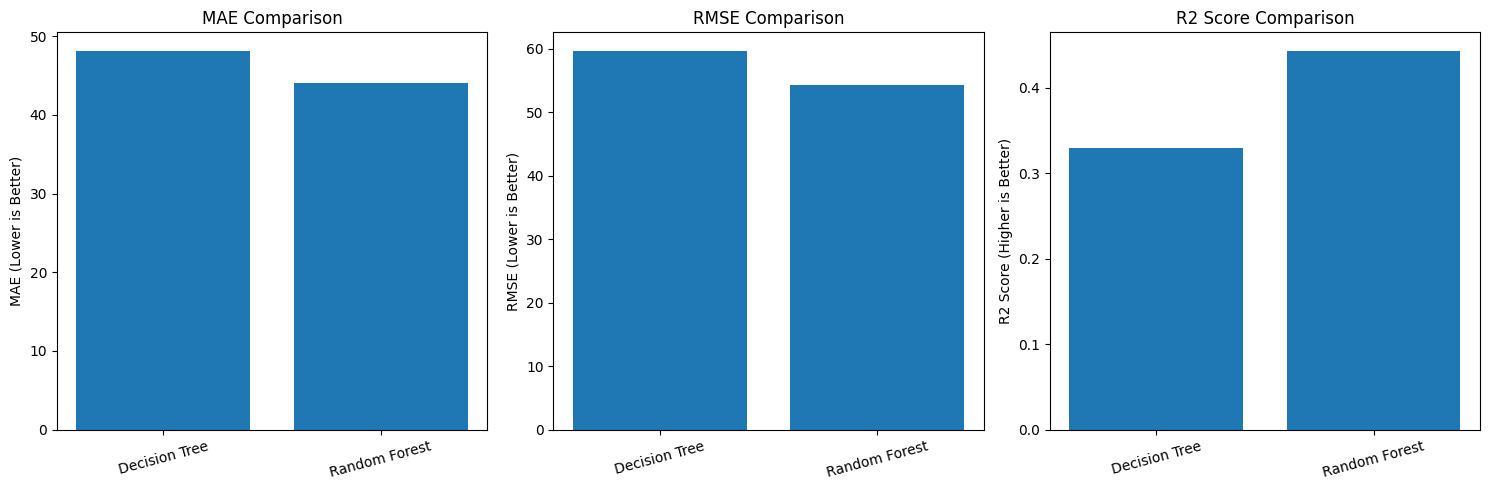

In [12]:
# Create 3 comparison charts
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

models = comparison["Model"]

# MAE Comparison
axes[0].bar(models, comparison["MAE"])
axes[0].set_title("MAE Comparison")
axes[0].set_ylabel("MAE (Lower is Better)")
axes[0].tick_params(axis="x", rotation=15)

# RMSE Comparison
axes[1].bar(models, comparison["RMSE"])
axes[1].set_title("RMSE Comparison")
axes[1].set_ylabel("RMSE (Lower is Better)")
axes[1].tick_params(axis="x", rotation=15)

# R2 Score Comparison
axes[2].bar(models, comparison["R2 Score"])
axes[2].set_title("R2 Score Comparison")
axes[2].set_ylabel("R2 Score (Higher is Better)")
axes[2].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()

#Step 13: Feature Importance

Feature Importance:
  Feature  Importance
2     bmi    0.355469
8      s5    0.230957
3      bp    0.088408
9      s6    0.071329
0     age    0.058642
5      s2    0.057227
4      s1    0.052784
6      s3    0.051339
7      s4    0.024213
1     sex    0.009633


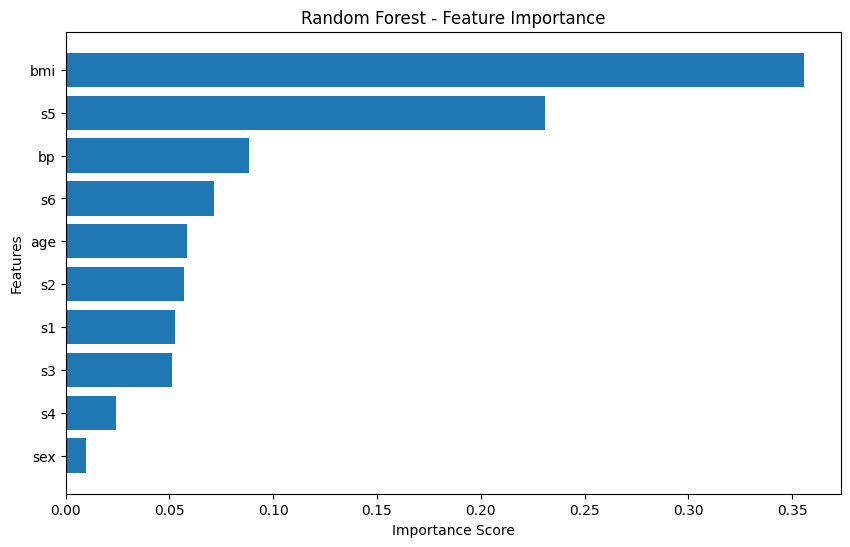

In [13]:
# Get feature importance from Random Forest
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
})

# Sort features by importance
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("Feature Importance:")
print(feature_importance)

# Visualize feature importance
plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.title("Random Forest - Feature Importance")

plt.gca().invert_yaxis()
plt.show()